In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_excel("Dry_Bean_Dataset.xlsx")
data

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13606,42097,759.696,288.721612,185.944705,1.552728,0.765002,42508,231.515799,0.714574,0.990331,0.916603,0.801865,0.006858,0.001749,0.642988,0.998385,DERMASON
13607,42101,757.499,281.576392,190.713136,1.476439,0.735702,42494,231.526798,0.799943,0.990752,0.922015,0.822252,0.006688,0.001886,0.676099,0.998219,DERMASON
13608,42139,759.321,281.539928,191.187979,1.472582,0.734065,42569,231.631261,0.729932,0.989899,0.918424,0.822730,0.006681,0.001888,0.676884,0.996767,DERMASON
13609,42147,763.779,283.382636,190.275731,1.489326,0.741055,42667,231.653248,0.705389,0.987813,0.907906,0.817457,0.006724,0.001852,0.668237,0.995222,DERMASON


In [3]:
print(data.info())
print(data.isnull().sum())
print("Duplicates:", data.duplicated().sum())
data.drop_duplicates(inplace=True)
print("Samples:", len(data))

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

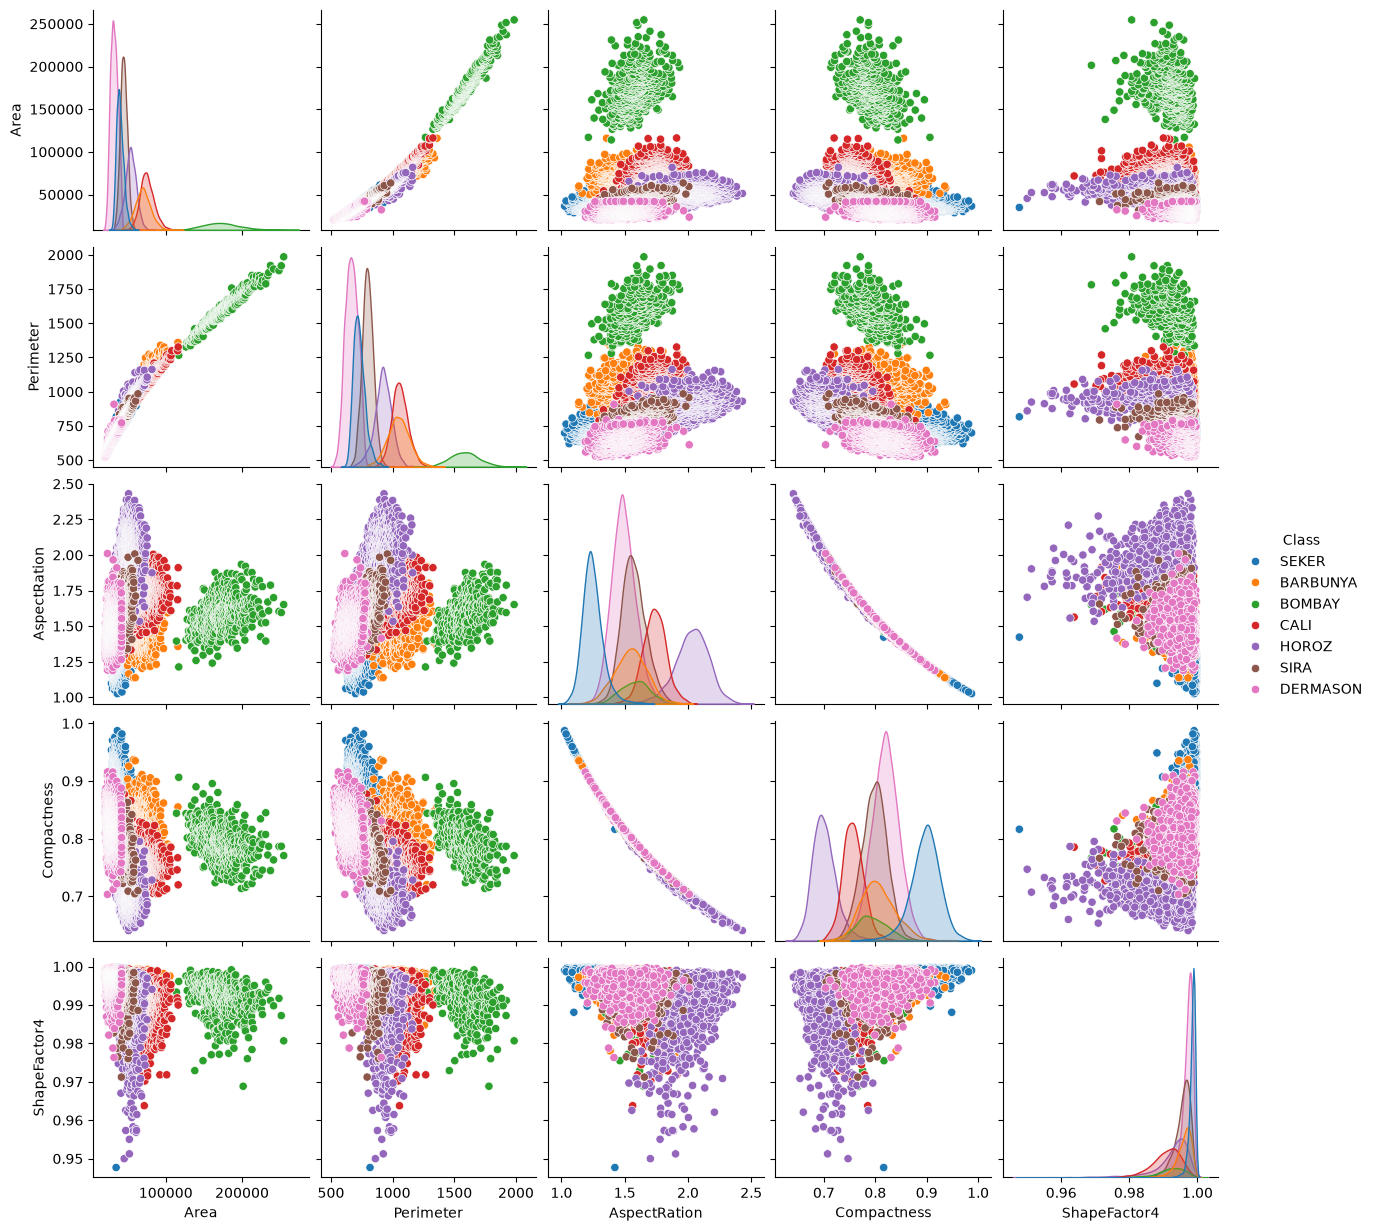

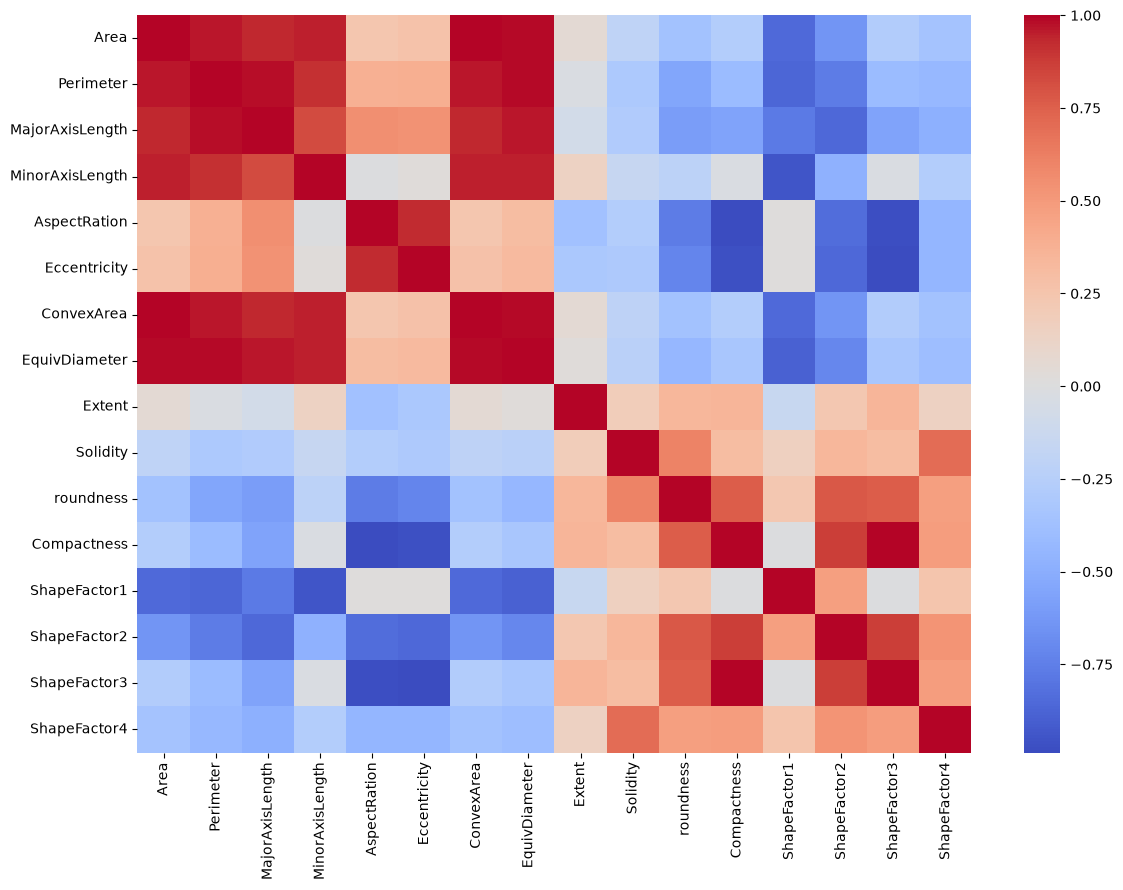

In [4]:
sns.pairplot(data=data, vars=["Area", "Perimeter", "AspectRation", "Compactness", "ShapeFactor4"], hue="Class")
plt.show()

plt.figure(figsize=(12, 9))
sns.heatmap(data.drop(columns="Class").corr(), cmap="coolwarm")
plt.tight_layout()
plt.show()
# Area separates BOMBAY; AspectRation and Compactness help separate SEKER and HOROZ.
# Area/ConvexArea and Compactness/ShapeFactor3 are highly correlated and redundant.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay

features = data.drop(columns="Class")
target = data["Class"]
Xtrain, Xtest, ytrain, ytest = train_test_split(features, target, test_size=0.2, random_state=42, stratify=target)

encoder = LabelEncoder()
ytrain_encoded = encoder.fit_transform(ytrain)
ytest_encoded = encoder.transform(ytest)
scalar = StandardScaler()
Xtrain_scaled = scalar.fit_transform(Xtrain)
Xtest_scaled = scalar.transform(Xtest)

In [6]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

dt_model = DecisionTreeClassifier()
dt_model.fit(Xtrain, ytrain_encoded)
ypred = dt_model.predict(Xtest)
print("Train:", dt_model.score(Xtrain, ytrain_encoded))
print("Test:", accuracy_score(ytest_encoded, ypred))
print(classification_report(ytest_encoded, ypred, target_names=encoder.classes_))

Train: 1.0
Test: 0.8999630860095976
              precision    recall  f1-score   support

    BARBUNYA       0.90      0.91      0.90       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.92      0.92       326
    DERMASON       0.89      0.90      0.89       709
       HOROZ       0.96      0.93      0.94       372
       SEKER       0.91      0.94      0.92       406
        SIRA       0.84      0.81      0.83       527

    accuracy                           0.90      2709
   macro avg       0.92      0.92      0.92      2709
weighted avg       0.90      0.90      0.90      2709



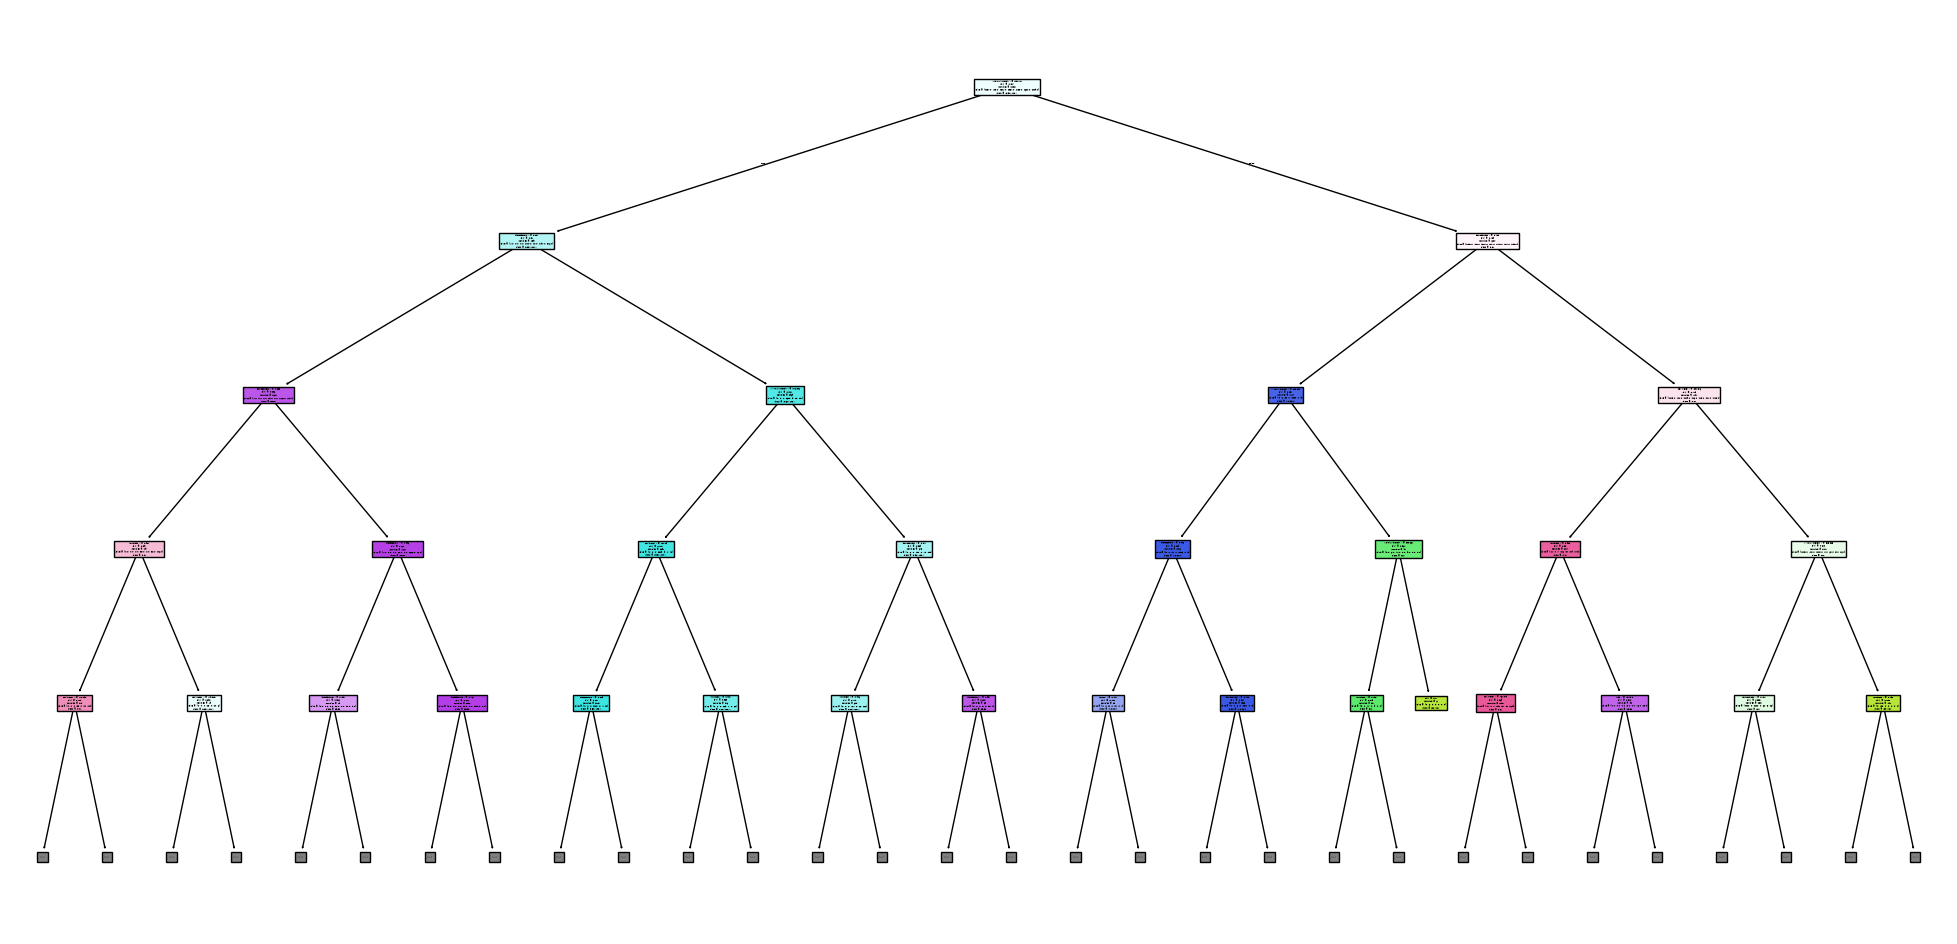

In [7]:
plt.figure(figsize=(25, 12))
plot_tree(dt_model, feature_names=features.columns, class_names=encoder.classes_, filled=True, max_depth=4)
plt.show()
# MajorAxisLength <= 280.70 mainly separates DERMASON/SEKER from the larger varieties.
# ShapeFactor1 <= 0.00682 helps separate SEKER from DERMASON.
# Compactness <= 0.72830 mainly separates HOROZ from SIRA/CALI/BARBUNYA.

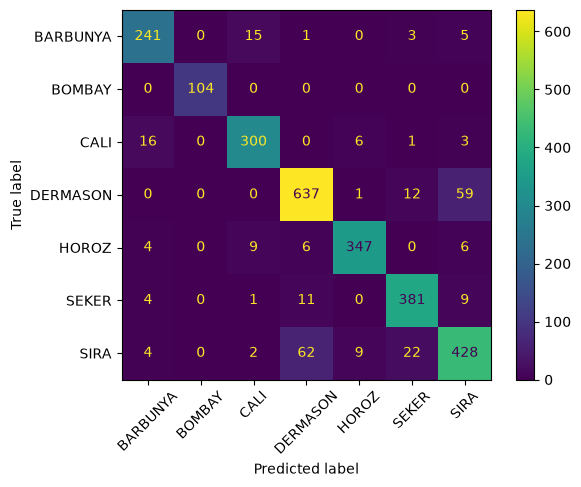

SIRA        99
DERMASON    72
CALI        26
HOROZ       25
SEKER       25
BARBUNYA    24
BOMBAY       0
dtype: int64


In [8]:
cm = confusion_matrix(ytest_encoded, ypred)
ConfusionMatrixDisplay(cm, display_labels=encoder.classes_).plot(xticks_rotation=45)
plt.show()
print(pd.Series(cm.sum(axis=1) - np.diag(cm), index=encoder.classes_).sort_values(ascending=False))
# SIRA and DERMASON are confused most often because their measurements overlap.

In [9]:
dt_models = []
for i in ["gini", "entropy"]:
  dt_models.append(DecisionTreeClassifier(criterion=i, random_state=42))
for i in [3, 5, 10, 15]:
  dt_models.append(DecisionTreeClassifier(max_depth=i, random_state=42))
alpha_values = [0, 0.0001, 0.0005, 0.001, 0.01]
for i in alpha_values:
  dt_models.append(DecisionTreeClassifier(ccp_alpha=i, random_state=42))

dt_results = []
for i in dt_models:
  i.fit(Xtrain, ytrain_encoded)
  dt_results.append([i.criterion, i.max_depth, i.ccp_alpha, i.score(Xtrain, ytrain_encoded), i.score(Xtest, ytest_encoded), i.get_depth()])

dt_compare = pd.DataFrame(dt_results, columns=["Criterion", "max_depth", "ccp_alpha", "Train Accuracy", "Test Accuracy", "Tree Depth"])
best_dt = dt_models[dt_compare["Test Accuracy"].idxmax()]
dt_compare

,Criterion,max_depth,ccp_alpha,Train Accuracy,Test Accuracy,Tree Depth
0,gini,NaN,0.0000,1.000000,0.895533,27
1,entropy,NaN,0.0000,1.000000,0.888889,18
2,gini,3.0,0.0000,0.777552,0.770026,3
3,gini,5.0,0.0000,0.890807,0.874862,5
4,gini,10.0,0.0000,0.965756,0.902178,10
5,gini,15.0,0.0000,0.993077,0.902916,15
6,gini,NaN,0.0000,1.000000,0.895533,27
7,gini,NaN,0.0001,0.989201,0.902547,27
8,gini,NaN,0.0005,0.932250,0.906238,10
9,gini,NaN,0.0010,0.921820,0.898856,9


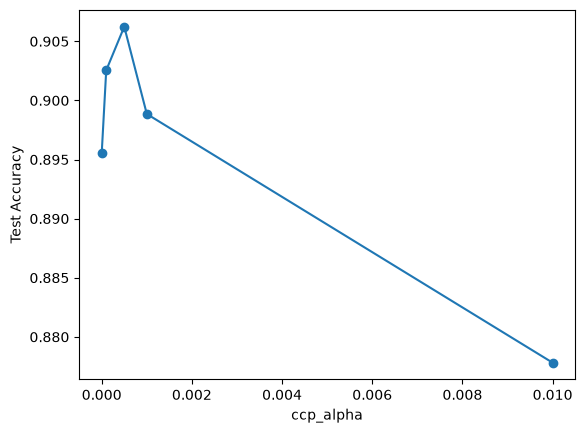

Best alpha: 0.0005


In [10]:
plt.plot(alpha_values, dt_compare.tail(5)["Test Accuracy"], marker="o")
plt.xlabel("ccp_alpha")
plt.ylabel("Test Accuracy")
plt.show()
print("Best alpha:", alpha_values[np.argmax(dt_compare.tail(5)["Test Accuracy"])] )
# Alpha 0.0005 gives a smaller tree and better test accuracy; strong pruning underfits.

Single SVM: 0.9210040605389442


Bagged SVM 0.9221114802510151


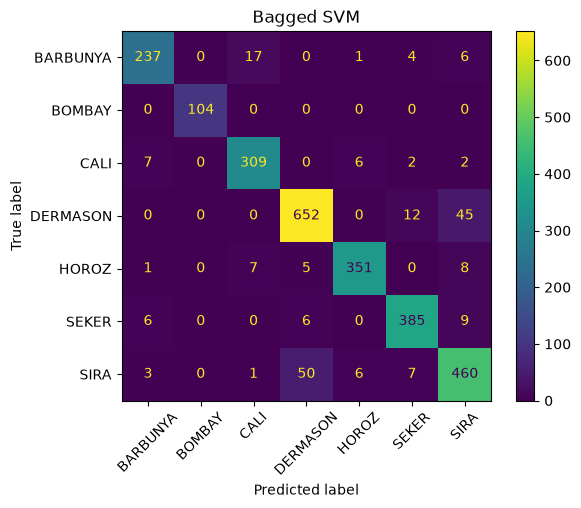

Bagged DT 0.9136212624584718


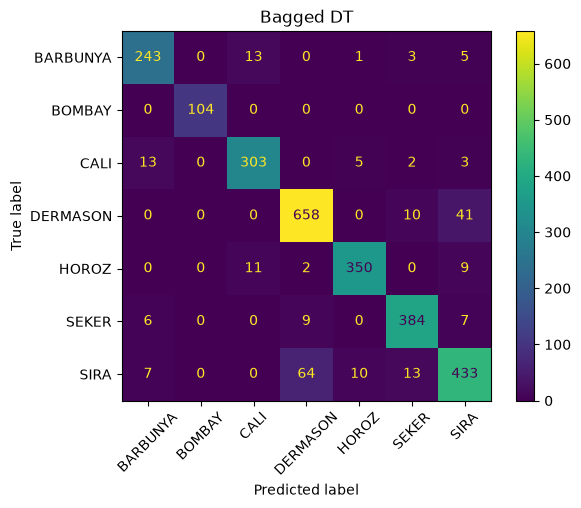

In [11]:
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

svm_classifier = SVC()
svm_classifier.fit(Xtrain_scaled, ytrain_encoded)
print("Single SVM:", svm_classifier.score(Xtest_scaled, ytest_encoded))

models = {"Decision Tree": best_dt}
for name, estimator in [("Bagged SVM", SVC()), ("Bagged DT", DecisionTreeClassifier())]:
  model = BaggingClassifier(estimator=estimator, n_estimators=10, random_state=42)
  model.fit(Xtrain_scaled, ytrain_encoded)
  models[name] = model
  print(name, model.score(Xtest_scaled, ytest_encoded))
  ConfusionMatrixDisplay.from_estimator(model, Xtest_scaled, ytest_encoded, display_labels=encoder.classes_, xticks_rotation=45)
  plt.title(name)
  plt.show()
# DT benefits more: bagging reduces its high variance; it cannot fix shared bias.

Random Forest: 0.9206349206349206


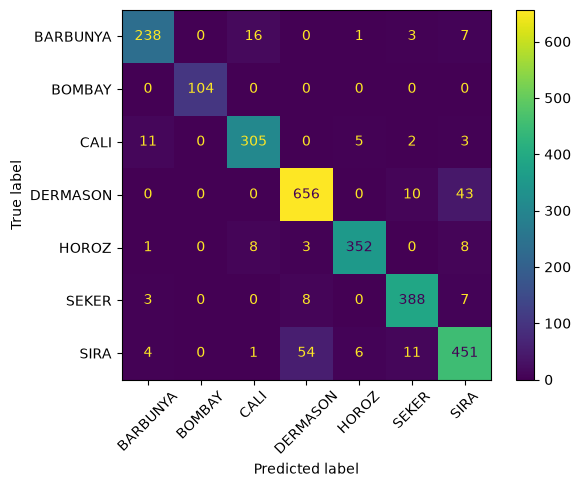

In [12]:
rfc = RandomForestClassifier(random_state=1)
rfc.fit(Xtrain_scaled, ytrain_encoded)
print("Random Forest:", rfc.score(Xtest_scaled, ytest_encoded))
ConfusionMatrixDisplay.from_estimator(rfc, Xtest_scaled, ytest_encoded, display_labels=encoder.classes_, xticks_rotation=45)
plt.show()

   n_estimators  Accuracy
0            10  0.907346
1            50  0.918789
2           100  0.920635
3           150  0.916944
4           200  0.918051


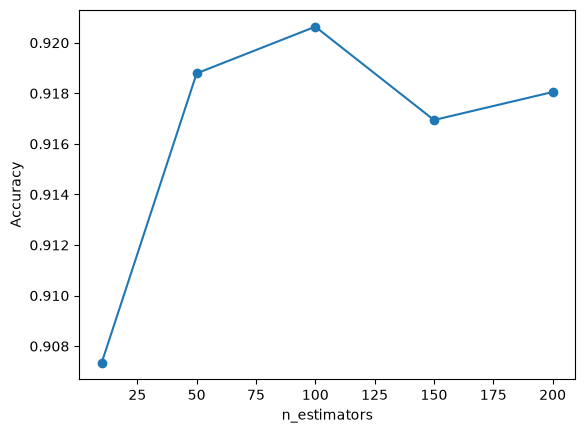

In [13]:
rf_estimators = [10, 50, 100, 150, 200]
rf_models = []
rf_accuracy = []
for i in rf_estimators:
  rfc = RandomForestClassifier(n_estimators=i, random_state=1)
  rfc.fit(Xtrain_scaled, ytrain_encoded)
  rf_models.append(rfc)
  rf_accuracy.append(rfc.score(Xtest_scaled, ytest_encoded))

best_rf_estimators = rf_estimators[np.argmax(rf_accuracy)]
print(pd.DataFrame({"n_estimators": rf_estimators, "Accuracy": rf_accuracy}))
plt.plot(rf_estimators, rf_accuracy, marker="o")
plt.xlabel("n_estimators")
plt.ylabel("Accuracy")
plt.show()
# Performance levels off around 50-100 trees; adding more trees does not improve it.

  max_features  Accuracy
0         sqrt  0.920635
1         log2  0.920635
2            8  0.920635


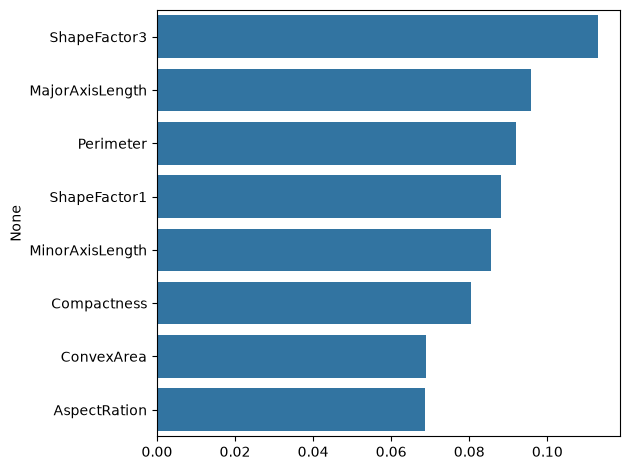

In [14]:
max_features = ["sqrt", "log2", 8]
rf_models = []
rf_accuracy = []
for i in max_features:
  rfc = RandomForestClassifier(n_estimators=best_rf_estimators, max_features=i, random_state=1)
  rfc.fit(Xtrain_scaled, ytrain_encoded)
  rf_models.append(rfc)
  rf_accuracy.append(rfc.score(Xtest_scaled, ytest_encoded))

models["Random Forest"] = rf_models[np.argmax(rf_accuracy)]
print(pd.DataFrame({"max_features": max_features, "Accuracy": rf_accuracy}))
importance = pd.Series(models["Random Forest"].feature_importances_, index=features.columns).sort_values(ascending=False)
sns.barplot(x=importance.head(8).values, y=importance.head(8).index)
plt.tight_layout()
plt.show()
# sqrt and log2 both use 4 features here; using 8 gives the same test accuracy.

   n_estimators  Accuracy
0            10  0.906608
1            50  0.916944
2           100  0.917682
3           200  0.915098
Best n_estimators: 100


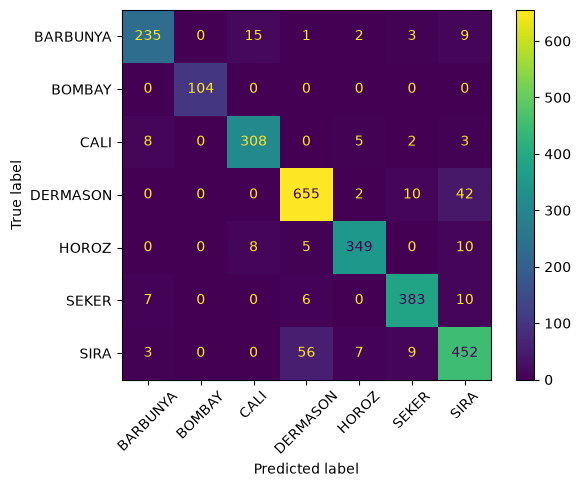

In [15]:
gb_estimators = [10, 50, 100, 200]
gb_models = []
gb_accuracy = []
for i in gb_estimators:
  gradient_classifier = GradientBoostingClassifier(n_estimators=i, random_state=42)
  gradient_classifier.fit(Xtrain_scaled, ytrain_encoded)
  gb_models.append(gradient_classifier)
  gb_accuracy.append(gradient_classifier.score(Xtest_scaled, ytest_encoded))

best_n_estimators = gb_estimators[np.argmax(gb_accuracy)]
gradient_classifier = gb_models[np.argmax(gb_accuracy)]
print(pd.DataFrame({"n_estimators": gb_estimators, "Accuracy": gb_accuracy}))
print("Best n_estimators:", best_n_estimators)
ConfusionMatrixDisplay.from_estimator(gradient_classifier, Xtest_scaled, ytest_encoded, display_labels=encoder.classes_, xticks_rotation=45)
plt.show()

   learning_rate  Accuracy
0            0.1  0.917682
1            0.3  0.909561
2            0.5  0.911776
3            0.9  0.903285
Best learning rate: 0.1


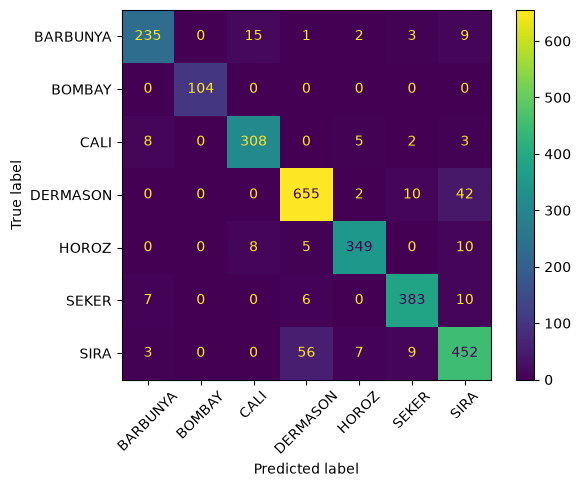

In [16]:
learning_rates = [0.1, 0.3, 0.5, 0.9]
gb_models = []
gb_accuracy = []
for i in learning_rates:
  gradient_classifier = GradientBoostingClassifier(n_estimators=best_n_estimators, learning_rate=i, random_state=42)
  gradient_classifier.fit(Xtrain_scaled, ytrain_encoded)
  gb_models.append(gradient_classifier)
  gb_accuracy.append(gradient_classifier.score(Xtest_scaled, ytest_encoded))

best_learning_rate = learning_rates[np.argmax(gb_accuracy)]
models["GradientBoosting"] = gb_models[np.argmax(gb_accuracy)]
print(pd.DataFrame({"learning_rate": learning_rates, "Accuracy": gb_accuracy}))
print("Best learning rate:", best_learning_rate)
ConfusionMatrixDisplay.from_estimator(models["GradientBoosting"], Xtest_scaled, ytest_encoded, display_labels=encoder.classes_, xticks_rotation=45)
plt.show()

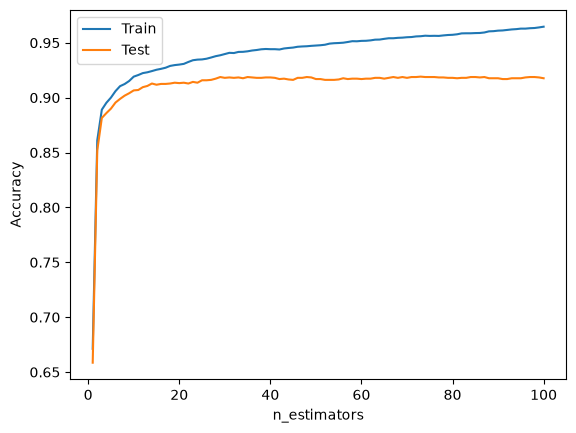

In [17]:
train_accuracy = []
test_accuracy = []
for i, j in zip(models["GradientBoosting"].staged_predict(Xtrain_scaled), models["GradientBoosting"].staged_predict(Xtest_scaled)):
  train_accuracy.append(accuracy_score(ytrain_encoded, i))
  test_accuracy.append(accuracy_score(ytest_encoded, j))
plt.plot(range(1, best_n_estimators + 1), train_accuracy, label="Train")
plt.plot(range(1, best_n_estimators + 1), test_accuracy, label="Test")
plt.xlabel("n_estimators")
plt.ylabel("Accuracy")
plt.legend()
plt.show()
# Training keeps improving while test accuracy levels off: signs of mild overfitting.

XGBoost: 0.9191583610188261


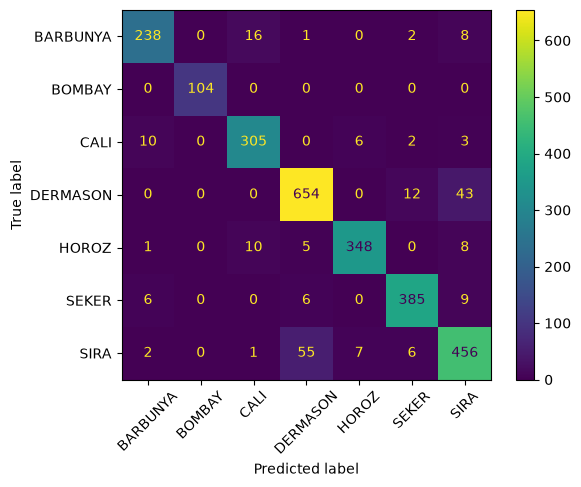

In [18]:
from xgboost import XGBClassifier

xgboost_classifier = XGBClassifier(n_estimators=best_n_estimators, learning_rate=best_learning_rate, random_state=42)
xgboost_classifier.fit(Xtrain_scaled, ytrain_encoded)
print("XGBoost:", xgboost_classifier.score(Xtest_scaled, ytest_encoded))
ConfusionMatrixDisplay.from_estimator(xgboost_classifier, Xtest_scaled, ytest_encoded, display_labels=encoder.classes_, xticks_rotation=45)
plt.show()

In [19]:
subsamples = [0.6, 0.8, 1.0]
xgb_models = []
xgb_accuracy = []
for i in subsamples:
  xgboost_classifier = XGBClassifier(n_estimators=best_n_estimators, learning_rate=best_learning_rate, subsample=i, random_state=42)
  xgboost_classifier.fit(Xtrain_scaled, ytrain_encoded)
  xgb_models.append(xgboost_classifier)
  xgb_accuracy.append(xgboost_classifier.score(Xtest_scaled, ytest_encoded))
models["XGBoost"] = xgb_models[np.argmax(xgb_accuracy)]
print(pd.DataFrame({"subsample": subsamples, "Accuracy": xgb_accuracy}))
# Subsampling reduces variance like bagging, but boosting trains sequentially and samples without replacement.

   subsample  Accuracy
0        0.6  0.922481
1        0.8  0.922111
2        1.0  0.919158


In [20]:
import time

results = []
for name, model in models.items():
  Xtrain_model = Xtrain if name == "Decision Tree" else Xtrain_scaled
  Xtest_model = Xtest if name == "Decision Tree" else Xtest_scaled
  start = time.time()
  model.fit(Xtrain_model, ytrain_encoded)
  training_time = time.time() - start
  ypred = model.predict(Xtest_model)
  report = classification_report(ytest_encoded, ypred, output_dict=True)["weighted avg"]
  results.append([name, report["precision"], report["recall"], accuracy_score(ytest_encoded, ypred), report["f1-score"], training_time])

comparison = pd.DataFrame(results, columns=["Model", "Precision", "Recall", "Accuracy", "F1-score", "Time (s)"])
comparison
# Bagging reduces variance; boosting corrects earlier errors and reduces bias.
# XGBoost leads by only one test sample over Bagged SVM; both work well here.
# GradientBoosting takes longest; XGBoost fits much faster on this dataset.

,Model,Precision,Recall,Accuracy,F1-score,Time (s)
0,Decision Tree,0.906398,0.906238,0.906238,0.905559,0.163983
1,Bagged SVM,0.922318,0.922111,0.922111,0.922136,1.212900
2,Bagged DT,0.913354,0.913621,0.913621,0.913268,0.751054
3,Random Forest,0.920629,0.920635,0.920635,0.920551,2.031299
4,GradientBoosting,0.917838,0.917682,0.917682,0.917670,23.375078
5,XGBoost,0.922496,0.922481,0.922481,0.922438,0.674145


In [21]:
for i in ["Precision", "Recall", "Accuracy", "F1-score"]:
  print(i, "Best:", comparison.loc[comparison[i].idxmax(), "Model"], "Worst:", comparison.loc[comparison[i].idxmin(), "Model"])
best_name = comparison.loc[comparison["Accuracy"].idxmax(), "Model"]
best_model = models[best_name]
print("Chosen model:", best_name)
# XGBoost wins all four metrics; Decision Tree is worst across all four.

Precision Best: XGBoost Worst: Decision Tree
Recall Best: XGBoost Worst: Decision Tree
Accuracy Best: XGBoost Worst: Decision Tree
F1-score Best: XGBoost Worst: Decision Tree
Chosen model: XGBoost


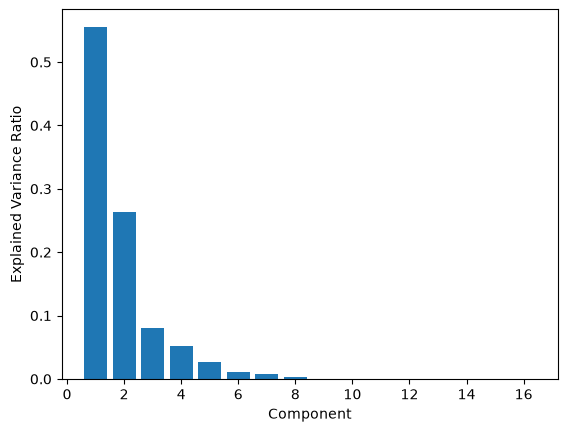

Components for 95% variance: 4


In [22]:
from sklearn.decomposition import PCA
from sklearn.base import clone

pca = PCA()
pca.fit(Xtrain_scaled)
plt.bar(range(1, 17), pca.explained_variance_ratio_)
plt.xlabel("Component")
plt.ylabel("Explained Variance Ratio")
plt.show()
n_components = np.argmax(np.cumsum(pca.explained_variance_ratio_) >= 0.95) + 1
print("Components for 95% variance:", n_components)

pca = PCA(n_components=n_components)
Xtrain_pca = pca.fit_transform(Xtrain_scaled)
Xtest_pca = pca.transform(Xtest_scaled)
pca_model = clone(best_model)
pca_model.fit(Xtrain_pca, ytrain_encoded)
pca_ypred = pca_model.predict(Xtest_pca)

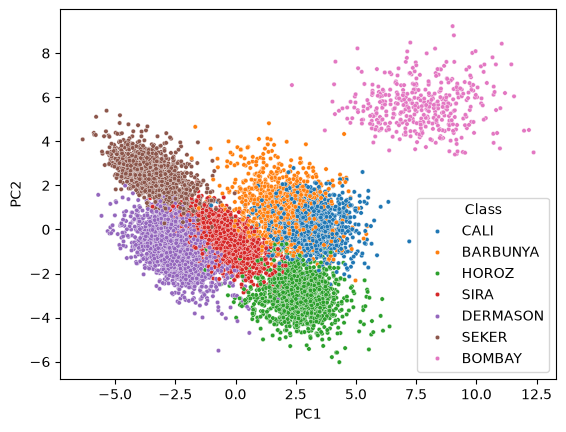

In [23]:
pca_data = pd.DataFrame(Xtrain_pca[:, :2], columns=["PC1", "PC2"])
pca_data["Class"] = ytrain.to_numpy()
sns.scatterplot(data=pca_data, x="PC1", y="PC2", hue="Class", s=10)
plt.show()

ShapeFactor3       0.112955
MajorAxisLength    0.095770
Perimeter          0.092055
ShapeFactor1       0.088156
MinorAxisLength    0.085672
Compactness        0.080558
ConvexArea         0.068874
AspectRation       0.068786
roundness          0.057483
Eccentricity       0.054317
EquivDiameter      0.050538
Area               0.047697
ShapeFactor2       0.036153
ShapeFactor4       0.030500
Solidity           0.019552
Extent             0.010933
dtype: float64


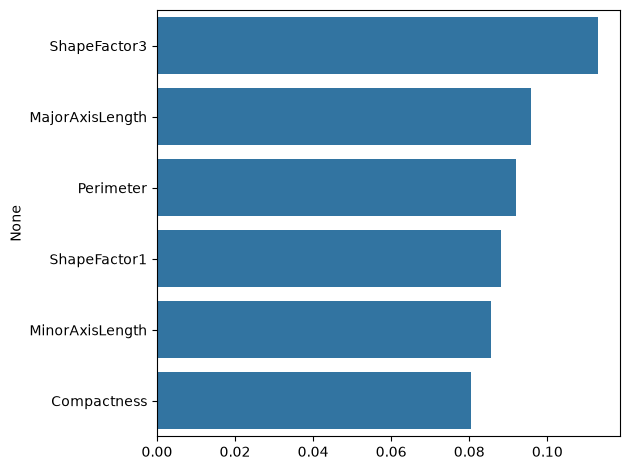

In [24]:
print(importance)
selected_features = importance.head(6).index
sns.barplot(x=importance.head(6).values, y=selected_features)
plt.tight_layout()
plt.show()

selected_scalar = StandardScaler()
Xtrain_selected = selected_scalar.fit_transform(Xtrain[selected_features])
Xtest_selected = selected_scalar.transform(Xtest[selected_features])
selected_model = clone(best_model)
selected_model.fit(Xtrain_selected, ytrain_encoded)
selected_ypred = selected_model.predict(Xtest_selected)

In [25]:
final = comparison[comparison["Model"] == best_name].drop(columns="Time (s)").reset_index(drop=True)
final.loc[0, "Model"] = "Original"
for name, ypred in [("PCA", pca_ypred), ("Top 6 Features", selected_ypred)]:
  report = classification_report(ytest_encoded, ypred, output_dict=True)["weighted avg"]
  final.loc[len(final)] = [name, report["precision"], report["recall"], accuracy_score(ytest_encoded, ypred), report["f1-score"]]
final.iloc[1:]

,Model,Precision,Recall,Accuracy,F1-score
1,PCA,0.886959,0.886305,0.886305,0.885991
2,Top 6 Features,0.909231,0.908822,0.908822,0.908800


In [26]:
final
# PCA uses 4 components but is harder to interpret; top 6 features keep their original meaning.
# Both lose accuracy here. I would deploy the original XGBoost for its better predictions, despite using all 16 features.

,Model,Precision,Recall,Accuracy,F1-score
0,Original,0.922496,0.922481,0.922481,0.922438
1,PCA,0.886959,0.886305,0.886305,0.885991
2,Top 6 Features,0.909231,0.908822,0.908822,0.908800
